# Đánh giá Improved CNN

Notebook này huấn luyện mô hình có BatchNorm và Dropout trên tập `train`, sau đó đánh giá một lần trên tập `test`. Các chỉ số và ma trận nhầm lẫn chỉ có ý nghĩa sau khi chạy lần lượt các ô từ trên xuống.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Hỗ trợ chạy notebook từ thư mục gốc repo hoặc từ notebooks/.
repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent

dataset_root = repo_root / "data" / "casting_data" / "casting_data"
train_dir = dataset_root / "train"
test_dir = dataset_root / "test"
if not train_dir.is_dir() or not test_dir.is_dir():
    raise FileNotFoundError(
        f"Không tìm thấy train/test trong {dataset_root}. "
        "Hãy kiểm tra vị trí dữ liệu casting_data."
    )

data_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

train_dataset = datasets.ImageFolder(root=train_dir, transform=data_transforms)
test_dataset = datasets.ImageFolder(root=test_dir, transform=data_transforms)
if train_dataset.classes != test_dataset.classes:
    raise ValueError(
        f"Danh sách lớp train/test không khớp: "
        f"{train_dataset.classes} != {test_dataset.classes}"
    )

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Thiết bị: {device}")
print(f"Số ảnh train: {len(train_dataset)} | Số ảnh test: {len(test_dataset)}")
print(f"Các lớp: {train_dataset.classes}")

Thiết bị: cpu
Số ảnh train: 6633 | Số ảnh test: 715
Các lớp: ['def_front', 'ok_front']


## 1. Xây dựng và huấn luyện Improved CNN

BatchNorm ổn định các activation; Dropout 0.4 được áp dụng ở tầng fully connected để giảm overfitting. Mô hình phải được huấn luyện trước khi tính các chỉ số trên tập test.

In [2]:
class ImprovedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(32 * 32 * 32, 128)
        self.fc2 = nn.Linear(128, 2)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)


model_improved = ImprovedCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_improved.parameters(), lr=0.001)

epochs = 3
print("Bắt đầu huấn luyện Improved CNN...")
for epoch in range(epochs):
    model_improved.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_improved(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predictions = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total
    print(
        f"Epoch {epoch + 1}/{epochs} - "
        f"Loss: {epoch_loss:.4f} | Accuracy: {epoch_accuracy:.2f}%"
    )

print("Huấn luyện hoàn tất.")

Bắt đầu huấn luyện Improved CNN...
Epoch 1/3 - Loss: 0.8541 | Accuracy: 83.60%
Epoch 2/3 - Loss: 0.2223 | Accuracy: 90.23%
Epoch 3/3 - Loss: 0.1858 | Accuracy: 91.26%
Huấn luyện hoàn tất.


## 2. Đánh giá trên tập test

Ô dưới đây chạy mô hình ở chế độ `eval()` (tắt Dropout), in precision/recall/F1/accuracy theo từng lớp và vẽ confusion matrix.

Đang đánh giá trên tập test...

BÁO CÁO PHÂN LOẠI:
              precision    recall  f1-score   support

   def_front       0.98      0.93      0.96       453
    ok_front       0.89      0.97      0.93       262

    accuracy                           0.95       715
   macro avg       0.94      0.95      0.94       715
weighted avg       0.95      0.95      0.95       715

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[422  31]
 [  7 255]]


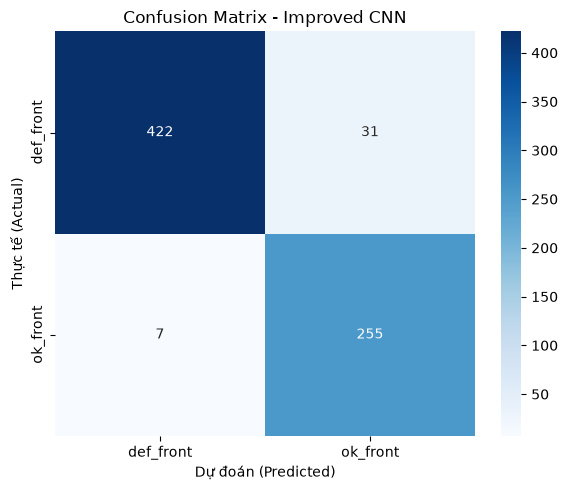

In [4]:
model_improved.eval()
all_preds = []
all_labels = []

print("Đang đánh giá trên tập test...")
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model_improved(images.to(device))
        all_preds.extend(outputs.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.tolist())

target_names = test_dataset.classes
print("\nBÁO CÁO PHÂN LOẠI:")
print(
    classification_report(
        all_labels,
        all_preds,
        labels=list(range(len(target_names))),
        target_names=target_names,
        zero_division=0,
    )
)

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(target_names))),
)
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(cm)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
)
plt.title("Confusion Matrix - Improved CNN")
plt.ylabel("Thực tế (Actual)")
plt.xlabel("Dự đoán (Predicted)")
plt.tight_layout()
plt.show()